# Lecture 5 · Autoencoders and the VAE, from the ELBO

[▶ Open in Colab](https://colab.research.google.com/github/nipunbatra/generative/blob/main/lectures/lecture5/lecture5-autoencoders-vae.ipynb) · [Slides](https://nipunbatra.github.io/generative/lectures/lecture5/) · [Lecture 5 at a glance](https://nipunbatra.github.io/generative/lectures/lecture5/#contents/1) · ES 667 Deep Learning, IIT Gandhinagar

This notebook runs the experiments behind the Lecture 5 slides, **in the same order and with the same section numbers** (1.1 … 6.2). Every slide's **▶ Notebook** link jumps to its section here.

The networks are Lecture 2's: a 2-number autoencoder, and 2-number and 16-number VAEs, trained there for 30 and 50 epochs. This notebook loads them and trains only a few small extra models for a few epochs each.

Run everything once from the top (*Runtime → Run all*). It needs PyTorch, torchvision, NumPy and matplotlib. In Colab it downloads MNIST (about 12 MB) and the three trained networks from the course repository; in a clone of the repository it uses the files in `lectures/lecture2/models`.

In [1]:
import math, os, urllib.request
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.distributions import Normal, kl_divergence
import matplotlib.pyplot as plt

torch.manual_seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
F64 = torch.float64
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False})
print('device:', DEVICE)

def show_digits(x, ncol=8, size=0.9, title=None):
    # Show a batch of 784-pixel images as ink on paper.
    x = torch.as_tensor(x).detach().float().cpu().reshape(-1, 28, 28).clamp(0, 1)
    n = len(x); nrow = math.ceil(n / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis('off')
        if i < n: ax.imshow(1 - x[i], cmap='gray', vmin=0, vmax=1)
    if title: fig.suptitle(title, fontsize=10)
    plt.show()

device: mps


# Part 1 · Why generate?

Generative models make new text, pictures and sound: a quick tour, what they are good for, and the one recipe they share.

## 1.1 Things that do not exist

Slides: [1.1 Things that do not exist](https://nipunbatra.github.io/generative/lectures/lecture5/#faces/1)

StyleGAN faces, then six real and six generated digits. The fakes are the first six draws z ~ N(0, I) through Lecture 2’s 16-number VAE; Section 5.7 makes more of them.

## 1.2 Text, pictures and sound

Slides: [1.2 Text, pictures and sound](https://nipunbatra.github.io/generative/lectures/lecture5/#llm/1)

A chatbot, a text-to-image model, image-to-image models and text to speech. Each one samples: the same prompt gives a different output every time. A language model gives a probability to every possible next word; generating is “sample a word, append it, repeat”.

## 1.3 What generative models are for

Slides: [1.3 What generative models are for](https://nipunbatra.github.io/generative/lectures/lecture5/#science/1)

Samples: create, fill in missing values, simulate many futures. Scores p(x): spot anomalies, compress (Lecture 1’s codes). And extra or synthetic data.

## 1.4 What they all share

Slides: [1.4 What they all share](https://nipunbatra.github.io/generative/lectures/lecture5/#recipe/1)

Random numbers in, a learned network, a sample out. A model of p(x) can score and sample. The average example is not a sample: load MNIST and look at the pixel-by-pixel average of the test 3s.

60,000 training and 10,000 test digits, 784 numbers each; test digit #90 is a 3


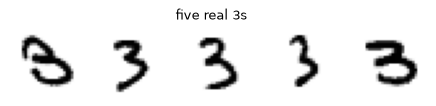

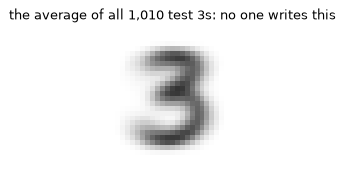

In [2]:
from torchvision.datasets import MNIST
MNIST_ROOT = os.environ.get('MNIST_ROOT', 'data')
have = (Path(MNIST_ROOT) / 'MNIST' / 'raw' / 'train-images-idx3-ubyte').exists()
train_set = MNIST(MNIST_ROOT, train=True, download=not have)
test_set = MNIST(MNIST_ROOT, train=False, download=not have)
Xtr = train_set.data.reshape(-1, 784).double() / 255; ytr = train_set.targets
Xte = test_set.data.reshape(-1, 784).double() / 255; yte = test_set.targets
x3 = Xte[90]
print(f'{len(Xtr):,} training and {len(Xte):,} test digits, {Xtr.shape[1]} numbers each; test digit #90 is a {int(yte[90])}')
threes = Xte[yte == 3]
show_digits(threes[:5], ncol=5, size=1.2, title='five real 3s')
show_digits(threes.mean(0)[None], ncol=1, size=2, title=f'the average of all {len(threes):,} test 3s: no one writes this')

# Part 2 · Autoencoders: squeeze, then rebuild

Squeeze each digit into 2 numbers, then rebuild it from them.

## 2.1 An image is 784 numbers

Slides: [2.1 An image is 784 numbers](https://nipunbatra.github.io/generative/lectures/lecture5/#mnist/1)

MNIST, grey levels scaled to [0, 1]. Our running example is test digit #90, a 3.

60,000 training and 10,000 test digits, 784 numbers each; test digit #90 is a 3


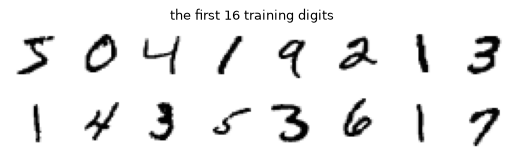

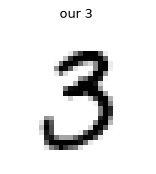

In [3]:
print(f'{len(Xtr):,} training and {len(Xte):,} test digits, {Xtr.shape[1]} numbers each; test digit #90 is a {int(yte[90])}')
show_digits(Xtr[:16], title='the first 16 training digits')
show_digits(x3[None], ncol=1, size=2, title='our 3')

## 2.2 Encoder, code, decoder

Slides: [2.2 Encoder, code, decoder](https://nipunbatra.github.io/generative/lectures/lecture5/#ae-arch/1)

One hidden layer of 400 ReLU units on each side, as in Kingma and Welling (2014). The same class becomes a VAE in Part 4.

In [4]:
class AutoEncoder(nn.Module):
    # variational=True: the encoder outputs a mean and a log variance per code number (Part 4).
    def __init__(self, z=2, variational=False):
        super().__init__()
        self.z, self.variational = z, variational
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU(), nn.Linear(400, 2 * z if variational else z))
        self.decoder = nn.Sequential(nn.Linear(z, 400), nn.ReLU(), nn.Linear(400, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x)
        return h.chunk(2, dim=1) if self.variational else (h, None)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu) if self.variational else mu
        return self.decoder(z), mu, logvar

SIGMA = 0.2                                              # the VAE's pixel noise (Part 4)
def loss_fn(model, x, target, beta=1.0):
    x_hat, mu, logvar = model(x)
    sse = ((x_hat - target) ** 2).sum(1)                 # squared error summed over the 784 pixels
    if not model.variational:
        return sse.mean()
    kl = 0.5 * (mu ** 2 + logvar.exp() - logvar - 1).sum(1)
    return (sse / (2 * SIGMA ** 2) + beta * kl).mean()

def train(model, epochs, beta=1.0, seed=0, lr=1e-3, log_every=None):
    torch.manual_seed(seed); model.to(DEVICE).train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    X = Xtr.float().to(DEVICE); step = 0
    for epoch in range(epochs):
        for idx in torch.randperm(len(X)).split(128):
            xb = X[idx]
            loss = loss_fn(model, xb, xb, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            if log_every and step % log_every == 0:
                print(f'step {step:4d}: loss {loss.item():7.2f}')
            step += 1
    return model.eval().cpu()

@torch.no_grad()
def test_sse(model, X=None):
    X = (Xte if X is None else X).float()
    mu, _ = model.encode(X)
    return float(((model.decoder(mu) - X) ** 2).sum(1).mean())

def load_trained(name, z, variational):
    # Lecture 2's networks: from lecture2/models in a clone, else downloaded from the repository.
    for path in (Path('..') / 'lecture2' / 'models' / f'{name}.pt', Path('models') / f'{name}.pt'):
        if path.exists(): break
    else:
        path.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/nipunbatra/generative/main/lectures/lecture2/models/{name}.pt', path)
    net = AutoEncoder(z, variational)
    net.load_state_dict(torch.load(path, map_location='cpu', weights_only=False)['state_dict'])
    return net.eval()

print(AutoEncoder(z=2))
print(f'encoder weights: {sum(p.numel() for p in AutoEncoder(z=2).encoder.parameters()):,}')

AutoEncoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
encoder weights: 314,802


## 2.3 The loss, and training

Slides: [2.3 The loss, and training](https://nipunbatra.github.io/generative/lectures/lecture5/#ae-loss/1)

Look at the untrained network first. Then load Lecture 2’s trained 2-number autoencoder (30 epochs), or set `RETRAIN = True` to train it here.

In [5]:
torch.manual_seed(0)
fresh = AutoEncoder(z=2).eval()
with torch.no_grad(): out = fresh(Xte[:8].float())[0]
print(f'untrained outputs lie between {out.min():.2f} and {out.max():.2f}; test squared error {test_sse(fresh):.1f} per image')
RETRAIN = False
ae2 = train(AutoEncoder(z=2), epochs=30) if RETRAIN else load_trained('ae2', 2, False)
print(f'trained: test squared error {test_sse(ae2):.2f} per image')

untrained outputs lie between 0.38 and 0.64; test squared error 182.5 per image
trained: test squared error 31.08 per image


### Our 3, pixel by pixel: target x, prediction x̂, and each pixel’s squared error

squared error of our 3, summed over 784 pixels: 26.31
row 24, col 10 (ink the network missed): x = 0.99, x_hat = 0.20, (x - x_hat)^2 = 0.63
row  5, col 11 (ink where the 3 has none): x = 0.00, x_hat = 0.65, (x - x_hat)^2 = 0.42
row  3, col 24 (background): x = 0.00, x_hat = 0.00, (x - x_hat)^2 = 0.00


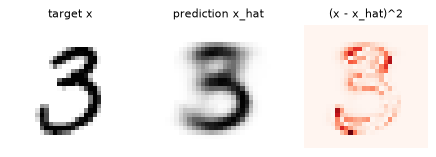

In [6]:
with torch.no_grad(): x3_hat = ae2.decoder(ae2.encode(x3[None].float())[0])[0].double()
err = (x3 - x3_hat) ** 2
print(f'squared error of our 3, summed over 784 pixels: {float(err.sum()):.2f}')
for (r, c), what in (((24, 10), 'ink the network missed'), ((5, 11), 'ink where the 3 has none'), ((3, 24), 'background')):
    j = r * 28 + c
    print(f'row {r:2d}, col {c:2d} ({what}): x = {x3[j]:.2f}, x_hat = {x3_hat[j]:.2f}, (x - x_hat)^2 = {err[j]:.2f}')
fig, ax = plt.subplots(1, 3, figsize=(6, 2.2))
for a, img, t, cmap in zip(ax, (1 - x3, 1 - x3_hat, err), ('target x', 'prediction x_hat', '(x - x_hat)^2'), ('gray', 'gray', 'Reds')):
    a.imshow(img.reshape(28, 28), cmap=cmap); a.set_title(t, fontsize=9); a.axis('off')
plt.show()

### Training in a few lines: one pass over the data, from scratch

In [7]:
demo = train(AutoEncoder(z=2), epochs=1, seed=1, log_every=100)
print(f'after one pass: test squared error {test_sse(demo):.1f} (Lecture 2’s 30 passes: {test_sse(ae2):.1f})')

step    0: loss  182.15
step  100: loss   45.51


step  200: loss   39.90
step  300: loss   41.40


step  400: loss   38.92
after one pass: test squared error 39.8 (Lecture 2’s 30 passes: 31.1)


## 2.4 What the code holds

Slides: [2.4 What the code holds](https://nipunbatra.github.io/generative/lectures/lecture5/#code-size/1)

Train autoencoders with wider codes (3 epochs each here; 30 on the slides), then plot where the 2-number codes land.

code of   2 numbers: test squared error  31.08
code of   8 numbers: test squared error  16.60
code of 128 numbers: test squared error   4.86


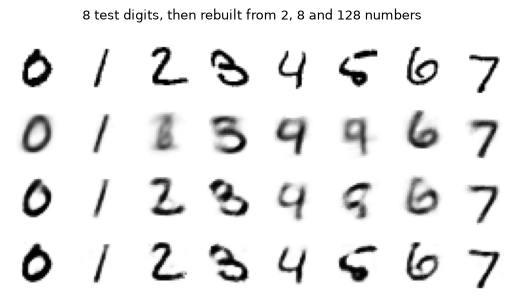

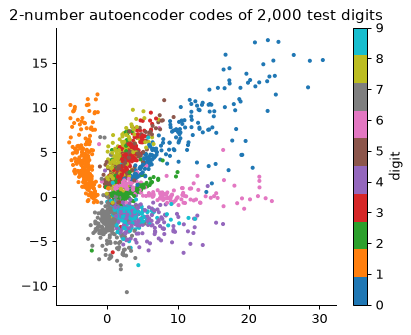

In [8]:
aes = {2: ae2}
for z in (8, 128):
    aes[z] = train(AutoEncoder(z=z), epochs=3, seed=z)
for z, net in aes.items():
    print(f'code of {z:3d} numbers: test squared error {test_sse(net):6.2f}')
idx = [3, 2, 1, 18, 4, 8, 11, 0]
with torch.no_grad():
    show_digits(torch.cat([Xte[idx].float()] + [net.decoder(net.encode(Xte[idx].float())[0]) for net in aes.values()]),
                title='8 test digits, then rebuilt from 2, 8 and 128 numbers')
with torch.no_grad(): C2 = ae2.encode(Xte[:2000].float())[0]
plt.figure(figsize=(5, 4)); plt.scatter(*C2.T, c=yte[:2000], cmap='tab10', s=5); plt.colorbar(label='digit')
plt.title('2-number autoencoder codes of 2,000 test digits'); plt.show()

# Part 3 · Can an autoencoder generate?

Keep the decoder, throw the encoder away, and invent the code.

## 3.1 Decode random codes

Slides: [3.1 Decode random codes](https://nipunbatra.github.io/generative/lectures/lecture5/#gen-question/1)

Feed draws from N(0, I) to the decoders.

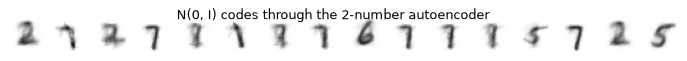

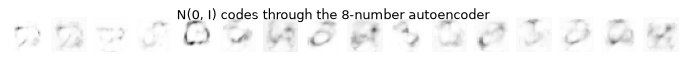

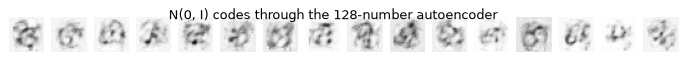

In [9]:
for z, net in aes.items():
    with torch.no_grad(): xs = net.decoder(torch.randn(16, z, generator=torch.Generator().manual_seed(5)))
    show_digits(xs, ncol=16, size=.6, title=f'N(0, I) codes through the {z}-number autoencoder')

## 3.2 Where the codes are

Slides: [3.2 Where the codes are](https://nipunbatra.github.io/generative/lectures/lecture5/#overlay/1)

Overlay N(0, I) draws on the codes of real test digits, then decode a grid of codes.

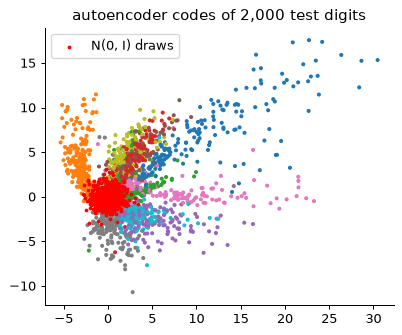

real codes run from [ -5.4 -10.7] to [30.5 17.6]


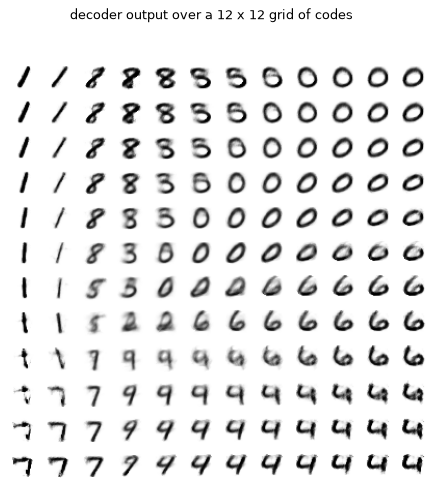

In [10]:
prior = torch.randn(500, 2, generator=torch.Generator().manual_seed(6))
plt.figure(figsize=(5, 4)); plt.scatter(*C2.T, c=yte[:2000], cmap='tab10', s=5); plt.scatter(*prior.T, s=4, c='red', label='N(0, I) draws')
plt.legend(); plt.title('autoencoder codes of 2,000 test digits'); plt.show()
print(f'real codes run from {C2.min(0).values.numpy().round(1)} to {C2.max(0).values.numpy().round(1)}')
lo, hi = C2.quantile(.01, 0), C2.quantile(.99, 0)
gx, gy = torch.linspace(lo[0], hi[0], 12), torch.linspace(hi[1], lo[1], 12)
grid = torch.stack(torch.meshgrid(gy, gx, indexing='ij')[::-1], -1).reshape(-1, 2)
with torch.no_grad(): show_digits(ae2.decoder(grid), ncol=12, size=.5, title='decoder output over a 12 x 12 grid of codes')

## 3.3 What we want instead

Slides: [3.3 What we want instead](https://nipunbatra.github.io/generative/lectures/lecture5/#wishes/1)

Codes that fill N(0, I); each image owning a small cloud of codes; one probability model that can score and sample. The VAE does all three.

# Part 4 · From an autoencoder to a VAE: three fixes

The autoencoder cannot generate. Three fixes, one at a time, turn it into a VAE.

## 4.1 Fix 1: choose where codes live

Slides: [4.1 Fix 1: choose where codes live](https://nipunbatra.github.io/generative/lectures/lecture5/#fix-prior/1)

Choose the distribution of codes in advance: z ~ N(0, I), two independent standard bells. Its draws pile up near the origin, with no gaps.

of 500 draws, 41% lie within distance 1 of the origin and 85% within 2 (in theory 39% and 86%)


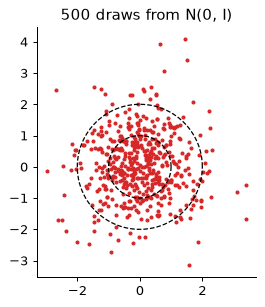

In [11]:
z = torch.randn(500, 2, generator=torch.Generator().manual_seed(0))
r = z.norm(dim=1)
print(f'of 500 draws, {float((r <= 1).float().mean()):.0%} lie within distance 1 of the origin and {float((r <= 2).float().mean()):.0%} within 2 (in theory 39% and 86%)')
t = torch.linspace(0, 2 * math.pi, 200)
plt.figure(figsize=(3.6, 3.6)); plt.scatter(*z.T, s=5, c='C3')
for k in (1, 2): plt.plot(k * t.cos(), k * t.sin(), 'k--', lw=1)
plt.gca().set_aspect('equal'); plt.title('500 draws from N(0, I)'); plt.show()

## 4.2 Fix 2: a cloud for each image

Slides: [4.2 Fix 2: a cloud for each image](https://nipunbatra.github.io/generative/lectures/lecture5/#fix-cloud/1)

Send each image to a small cloud N(μ, σ²) instead of a point. The encoder outputs μ and log σ²; the code is drawn with Lecture 1’s reparameterisation trick (tool ①), so gradients still reach μ and σ.

In [12]:
# Tool 1: a random draw that gradients pass through.
mu = torch.tensor([0.5, -1.0], requires_grad=True)
log_sigma = torch.tensor([0.0, -0.5], requires_grad=True)
eps = torch.randn(2, generator=torch.Generator().manual_seed(0))
z = mu + log_sigma.exp() * eps          # the randomness sits in eps
z.sum().backward()
print('z =', z.detach().numpy().round(3))
print('dz/dmu =', mu.grad.numpy(), '  dz/dlog_sigma =', log_sigma.grad.numpy().round(3), '(= sigma * eps)')

z = [ 2.041 -1.178]
dz/dmu = [1. 1.]   dz/dlog_sigma = [ 1.541 -0.178] (= sigma * eps)


## 4.3 Fix 3: pull the clouds to N(0, I)

Slides: [4.3 Fix 3: pull the clouds to N(0, I)](https://nipunbatra.github.io/generative/lectures/lecture5/#fix-kl/1)

Charge each cloud for being unlike N(0, 1) with Lecture 1’s KL, by formula (tool ②): ½(μ² + σ² − log σ² − 1). A cloud far away costs, and so does a cloud shrunk to a point.

In [13]:
# Tool 2: the KL from N(mu, sigma^2) to N(0, 1), three ways.
def kl_to_std_normal(m, s):
    return 0.5 * (m ** 2 + s ** 2 - math.log(s ** 2) - 1)
m_, s_ = 2.0, 1.0
draws = Normal(m_, s_).sample((200_000,), )
mc = float((Normal(m_, s_).log_prob(draws) - Normal(0., 1.).log_prob(draws)).mean())
print(f'formula {kl_to_std_normal(m_, s_):.4f}   torch {float(kl_divergence(Normal(m_, s_), Normal(0., 1.))):.4f}   Monte Carlo {mc:.4f}')
print(f'at mu = 0, sigma = 1 the KL is {kl_to_std_normal(0.0, 1.0):.1f}')
for m_, s_, what in ((0.0, 1.0, 'exactly N(0, 1)'), (5.0, 1.0, 'far from the centre'), (0.0, 0.01, 'shrunk almost to a point')):
    print(f'{what:26s} mu = {m_:4.1f}, sigma = {s_:5.2f}: penalty {kl_to_std_normal(m_, s_):5.1f}')

formula 2.0000   torch 2.0000   Monte Carlo 1.9949
at mu = 0, sigma = 1 the KL is 0.0
exactly N(0, 1)            mu =  0.0, sigma =  1.00: penalty   0.0
far from the centre        mu =  5.0, sigma =  1.00: penalty  12.5
shrunk almost to a point   mu =  0.0, sigma =  0.01: penalty   4.1


## 4.4 The loss the fixes give

Slides: [4.4 The loss the fixes give](https://nipunbatra.github.io/generative/lectures/lecture5/#fix-loss/1)

Rebuild the image from a draw of its cloud, plus the KL that pulls the cloud towards N(0, I): L = ‖x − f(μ + σ ⊙ ε)‖² + KL(N(μ, σ²) ‖ N(0, I)). Part 5 shows this is minus the ELBO, with a weight of 1/2σ² on the first term.

# Part 5 · Why this loss: Lecture 1’s ELBO, one image at a time

A model with a hidden code: z ~ N(0, I), x | z ~ N(decoder(z), 0.2² I). Lecture 2’s trained VAEs (50 epochs).

## 5.1 What Lecture 1 gave us

Slides: [5.1 What Lecture 1 gave us](https://nipunbatra.github.io/generative/lectures/lecture5/#recap-elbo/1)

The objective: maximise the ELBO = E_q[log-likelihood] − KL(q ‖ prior). log p(𝒟) = ELBO + KL(q ‖ posterior), so raising the ELBO lowers the KL to the posterior.

## 5.2 A model with a hidden code

Slides: [5.2 A model with a hidden code](https://nipunbatra.github.io/generative/lectures/lecture5/#vae-pgm/1)

To draw an image, follow the arrows: first z from the prior, then the decoder, then pixel noise.

z = [[0.8  0.17]]


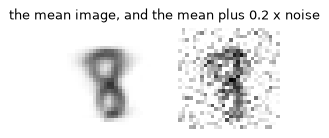

the constant 784 log(sigma sqrt(2 pi)) = -541.35


In [14]:
vae2 = load_trained('vae2', 2, True); vae16 = load_trained('vae16', 16, True)
z = torch.randn(1, 2, generator=torch.Generator().manual_seed(3))
with torch.no_grad(): mean = vae2.decoder(z)
x_sample = mean + SIGMA * torch.randn(mean.shape, generator=torch.Generator().manual_seed(4))
print('z =', z.numpy().round(2))
show_digits(torch.cat([mean, x_sample.clamp(0, 1)]), ncol=2, size=1.6, title='the mean image, and the mean plus 0.2 x noise')
const = 784 * math.log(SIGMA * math.sqrt(2 * math.pi))
@torch.no_grad()
def log_lik(net, x, Z):                     # log p(x | z) for a batch of codes Z
    return -((net.decoder(Z.float()).double() - x) ** 2).sum(1) / (2 * SIGMA ** 2) - const
print(f'the constant 784 log(sigma sqrt(2 pi)) = {const:.2f}')

## 5.3 The same wall as Lecture 1

Slides: [5.3 The same wall as Lecture 1](https://nipunbatra.github.io/generative/lectures/lecture5/#vae-wall/1)

p(x) is an integral over every code. With only 2 numbers we can still add up rectangles on a fine grid; with 16 we could not.

log p(x) by adding rectangles: 244.07
posterior of our 3: mean [-0.2261  0.0608]  sd [0.0183 0.014 ]


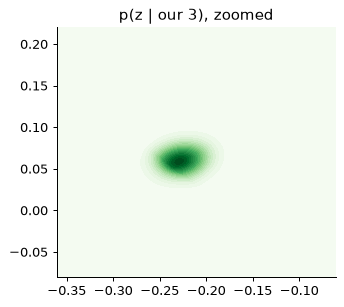

In [15]:
with torch.no_grad(): mu3, lv3 = vae2.encode(x3[None].float())
mu3, sd3 = mu3[0].double(), (0.5 * lv3[0].double()).exp()
half, n = 0.15, 241                                  # a fine window around the posterior
ax_x = torch.linspace(mu3[0] - half, mu3[0] + half, n, dtype=F64); ax_y = torch.linspace(mu3[1] - half, mu3[1] + half, n, dtype=F64)
Zg = torch.stack(torch.meshgrid(ax_x, ax_y, indexing='xy'), -1).reshape(-1, 2)
lj = log_lik(vae2, x3, Zg) - 0.5 * (Zg ** 2).sum(1) - math.log(2 * math.pi)    # log p(x | z) + log p(z)
cell = float((ax_x[1] - ax_x[0]) * (ax_y[1] - ax_y[0]))
log_px = float(torch.logsumexp(lj, 0)) + math.log(cell)
post = torch.softmax(lj, 0)
pm = (post[:, None] * Zg).sum(0); ps = ((post[:, None] * (Zg - pm) ** 2).sum(0)).sqrt()
print(f'log p(x) by adding rectangles: {log_px:.2f}')
print('posterior of our 3: mean', pm.numpy().round(4), ' sd', ps.numpy().round(4))
plt.figure(figsize=(4, 3.6)); plt.contourf(ax_x, ax_y, post.reshape(n, n), levels=20, cmap='Greens'); plt.title('p(z | our 3), zoomed'); plt.show()

## 5.4 The ELBO for one image

Slides: [5.4 The ELBO for one image](https://nipunbatra.github.io/generative/lectures/lecture5/#vae-elbo/1)

ELBO(x) = E_q[log p(x | z)] − KL(q(z | x) ‖ p(z)). The encoder gives q for our 3 in one pass; its ELBO sits just below log p(x).

In [16]:
def elbo(net, x, m_, s_, draws=20000, seed=21):
    eps = torch.randn(draws, 2, generator=torch.Generator().manual_seed(seed), dtype=F64)
    kl = 0.5 * float((m_ ** 2 + s_ ** 2 - 2 * s_.log() - 1).sum())
    return float(log_lik(net, x, m_ + s_ * eps).mean()) - kl

print('encoder q for our 3: mean', mu3.numpy().round(4), ' sd', sd3.numpy().round(4))
e3 = elbo(vae2, x3, mu3, sd3)
print(f'log p(x) {log_px:.2f}  |  ELBO with the encoder’s q {e3:.2f}  |  gap = KL to the posterior {log_px - e3:.2f}')

encoder q for our 3: mean [-0.2106  0.0702]  sd [0.013  0.0104]
log p(x) 244.07  |  ELBO with the encoder’s q 243.37  |  gap = KL to the posterior 0.70


### Lecture 1’s variational inference on this one image: fit q(z) = N(m, diag s²) by maximising the ELBO

In [17]:
torch.manual_seed(23)
m_q = torch.zeros(2, requires_grad=True); log_s = torch.zeros(2, requires_grad=True)     # start at the prior N(0, I)
opt = torch.optim.Adam([m_q, log_s], lr=0.05)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: 1.0 if t < 800 else 0.2)
x3f = x3.float()
for step in range(1200):
    zq = m_q + log_s.exp() * torch.randn(64, 2)                                  # tool 1: reparameterised draws
    log_lik_q = -((vae2.decoder(zq) - x3f) ** 2).sum(1) / (2 * SIGMA ** 2) - const
    kl_q = 0.5 * (m_q ** 2 + (2 * log_s).exp() - 2 * log_s - 1).sum()                # tool 2: the KL by formula
    loss = -(log_lik_q.mean() - kl_q)                                             # minus the ELBO
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
m_vi, s_vi = m_q.detach().double(), log_s.detach().double().exp()
print('per-image q: mean', m_vi.numpy().round(4), ' sd', s_vi.numpy().round(4))
print(f'log p(x) {log_px:.2f}  |  ELBO, q fitted to this image {elbo(vae2, x3, m_vi, s_vi):.2f}  |  ELBO, encoder in one pass {e3:.2f}')

per-image q: mean [-0.2275  0.062 ]  sd [0.0182 0.015 ]
log p(x) 244.07  |  ELBO, q fitted to this image 244.05  |  ELBO, encoder in one pass 243.37


## 5.5 The loss, term by term

Slides: [5.5 The loss, term by term](https://nipunbatra.github.io/generative/lectures/lecture5/#vae-loss/1)

One reparameterised draw for our 3, with ε = (0.5, −1.0).

In [18]:
eps = torch.tensor([0.5, -1.0], dtype=F64)
z = mu3 + sd3 * eps
with torch.no_grad(): xh = vae2.decoder(z[None].float())[0].double()
sse = float(((xh - x3) ** 2).sum()); kl = 0.5 * float((mu3 ** 2 + sd3 ** 2 - 2 * sd3.log() - 1).sum())
print(f'z = {z.numpy().round(4)}')
print(f'squared error {sse:.2f}; reconstruction term {sse / (2 * SIGMA ** 2):.1f}; KL {kl:.2f}; loss {sse / (2 * SIGMA ** 2) + kl:.1f}')

z = [-0.2042  0.0599]
squared error 23.18; reconstruction term 289.8; KL 7.94; loss 297.7


## 5.6 Both terms, live

Slides: [5.6 Both terms, live](https://nipunbatra.github.io/generative/lectures/lecture5/#elbo-explorer/1)

The reconstruction term wants tiny, separated clouds; the KL wants every cloud to be N(0, I). Averages over the 10,000 test digits:

In [19]:
with torch.no_grad():
    mu_, lv_ = vae2.encode(Xte.float())
    kl_te = 0.5 * (mu_ ** 2 + lv_.exp() - lv_ - 1).sum(1).mean()
print(f'2-number VAE: squared error {test_sse(vae2):.2f}, KL {kl_te:.2f} per image, average sigma of q {torch.exp(0.5 * lv_).mean():.4f}')
print(f'2-number autoencoder: squared error {test_sse(ae2):.2f}')

2-number VAE: squared error 30.77, KL 9.02 per image, average sigma of q 0.0354
2-number autoencoder: squared error 31.08


### Choose q for our 3 yourself, as on the slide: the reconstruction term, the KL to the prior and the ELBO

In [20]:
xs_gh, ws_gh = np.polynomial.hermite.hermgauss(8)                 # 8 x 8 Gauss-Hermite nodes for E over eps ~ N(0, I)
E_gh = torch.tensor([[math.sqrt(2) * a, math.sqrt(2) * b] for a in xs_gh for b in xs_gh], dtype=F64)
W_gh = torch.tensor([wa * wb / math.pi for wa in ws_gh for wb in ws_gh], dtype=F64)
@torch.no_grad()
def terms(mu, s):
    mu = torch.as_tensor(mu, dtype=F64)
    recon = float((W_gh * ((vae2.decoder((mu + s * E_gh).float()).double() - x3) ** 2).sum(1)).sum()) / (2 * SIGMA ** 2)
    kl = 0.5 * float((mu ** 2).sum() + 2 * s ** 2 - 2 * math.log(s ** 2) - 2)
    return recon, kl, -recon - kl - const
for name, mu, s in (('the encoder’s q', mu3, float((sd3[0] * sd3[1]).sqrt())), ('q = N(0, I)', [0.0, 0.0], 1.0),
                    ('q on the 1s', [0.0, 3.2], 0.05)):                 # mu = (0, 3.2): where the VAE puts its 1s
    r, k, e = terms(mu, s)
    print(f'{name:16s} reconstruction {r:8.1f}   KL {k:6.1f}   ELBO {e:8.1f}   gap to log p(x) {log_px - e:7.1f}')

the encoder’s q  reconstruction    290.1   KL    7.9   ELBO    243.3   gap to log p(x)     0.7
q = N(0, I)      reconstruction    811.0   KL    0.0   ELBO   -269.7   gap to log p(x)   513.7
q on the 1s      reconstruction   1045.3   KL   10.1   ELBO   -514.1   gap to log p(x)   758.1


## 5.7 What the VAE learned

Slides: [5.7 What the VAE learned](https://nipunbatra.github.io/generative/lectures/lecture5/#vae-samples/1)

Sample z ~ N(0, I) and decode; look at where the codes are.

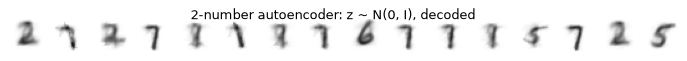

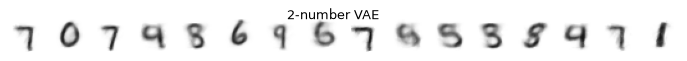

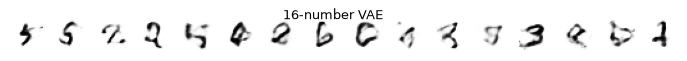

VAE codes of all test digits: mean [-0.2  -0.25]  sd [1.75 1.72]


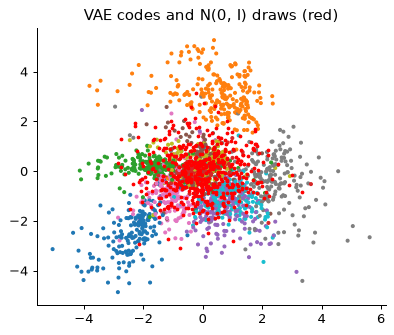

In [21]:
with torch.no_grad():
    show_digits(ae2.decoder(torch.randn(16, 2, generator=torch.Generator().manual_seed(5))), ncol=16, size=.6, title='2-number autoencoder: z ~ N(0, I), decoded')
    show_digits(vae2.decoder(torch.randn(16, 2, generator=torch.Generator().manual_seed(5))), ncol=16, size=.6, title='2-number VAE')
    show_digits(vae16.decoder(torch.randn(16, 16, generator=torch.Generator().manual_seed(5))), ncol=16, size=.6, title='16-number VAE')
    V2 = vae2.encode(Xte.float())[0]
print('VAE codes of all test digits: mean', V2.mean(0).numpy().round(2), ' sd', V2.std(0).numpy().round(2))
plt.figure(figsize=(5, 4)); plt.scatter(*V2[:2000].T, c=yte[:2000], cmap='tab10', s=5); plt.scatter(*prior.T, s=4, c='red')
plt.title('VAE codes and N(0, I) draws (red)'); plt.show()

## 5.8 The KL weight β

Slides: [5.8 The KL weight β](https://nipunbatra.github.io/generative/lectures/lecture5/#beta-what/1)

Train 2-number VAEs with β = 0 and β = 256 (5 epochs each here; 50 in Lecture 2) and compare with β = 1.

In [22]:
for beta, net in ((0.0, train(AutoEncoder(2, True), epochs=5, beta=0.0, seed=40)), (1.0, vae2), (256.0, train(AutoEncoder(2, True), epochs=5, beta=256.0, seed=41))):
    with torch.no_grad():
        mu_, lv_ = net.encode(Xte.float())
        kl = 0.5 * (mu_ ** 2 + lv_.exp() - lv_ - 1).sum(1).mean()
    print(f'beta = {beta:5.0f}: KL per image {kl:6.2f}, average sigma of q {torch.exp(0.5 * lv_).mean():.4f}, spread of codes {mu_.std(0).mean():.2f}')

beta =     0: KL per image  31.93, average sigma of q 0.0059, spread of codes 4.00
beta =     1: KL per image   9.02, average sigma of q 0.0354, spread of codes 1.74
beta =   256: KL per image   0.00, average sigma of q 0.9990, spread of codes 0.00


# Part 6 · Putting it together

Every piece of the lecture on one page: the VAE’s loss, term by term, traced back to KL and the ELBO.

## 6.1 The whole lecture in maths

Slides: [6.1 The whole lecture in maths](https://nipunbatra.github.io/generative/lectures/lecture5/#maths-chain/1)

① KL(q ‖ p) = E_q[log q − log p] ≥ 0. ② log p(x) = ELBO(x) + KL(q(z | x) ‖ p(z | x)). ③ ELBO(x) = E_q[log p(x | z)] − KL(q(z | x) ‖ p(z)). ④ −log p(x | z) = ‖x − f(z)‖² / 2σ² + const. ⑤ z = μ + σ ⊙ ε and the Gaussian KL by formula. Below, all five for our 3 from scratch.

In [23]:
x = x3.float()[None]
with torch.no_grad():
    mu, logvar = vae2.encode(x)                                     # the encoder: q(z | x) = N(mu, diag sigma^2)
    sigma = (0.5 * logvar).exp()
    eps = torch.randn(1000, 2, generator=torch.Generator().manual_seed(7))
    z = mu + sigma * eps                                            # (5) tool 1: reparameterised draws
    recon = ((vae2.decoder(z) - x) ** 2).sum(1) / (2 * SIGMA ** 2)  # (4) Gaussian pixels: -log p(x | z) - const
    kl = 0.5 * (mu ** 2 + sigma ** 2 - logvar - 1).sum()            # (5) tool 2: the KL to N(0, I), by formula
    elbo_x = -(recon.mean() + kl) - const                           # (3) the ELBO's two terms
print(f'reconstruction {recon.mean():.1f} + KL {kl:.2f} = loss {recon.mean() + kl:.1f}')
print(f'ELBO {elbo_x:.2f} <= log p(x) {log_px:.2f}: the gap {log_px - float(elbo_x):.2f} is the KL to the posterior (1, 2)')

reconstruction 290.1 + KL 7.94 = loss 298.0
ELBO 243.35 <= log p(x) 244.07: the gap 0.72 is the KL to the posterior (1, 2)


## 6.2 Wrap-up

Slides: [6.2 Wrap-up](https://nipunbatra.github.io/generative/lectures/lecture5/#summary/1)

A VAE is an autoencoder trained with Lecture 1’s objective: the encoder outputs a cloud, the code is a reparameterised draw, and the loss adds a KL to N(0, I). Next lectures replace the pixel-wise Gaussian likelihood: GANs, then diffusion.

# Appendix · optional slides

The optional slides reuse Lecture 2’s experiments, and Lecture 2’s [notebook](https://colab.research.google.com/github/nipunbatra/generative/blob/main/lectures/lecture2/lecture2-generative-models.ipynb) has the code for each: PCA against the autoencoder, random codes and straight-line walks between digits, per-image variational inference for our 3 against the encoder’s q, and the β sweep.